# Football playing styles: unsupervised clusters and an interactive UMAP

**Question:** Do players with the same official position have different measurable playing
styles, and do similar styles occur across different positions?

This is a separate exploratory study of the full player-statistics CSV. **Position labels
are never passed to imputation, scaling, K-means, UMAP, or cluster naming.** They are used to
exclude goalkeepers when defining the cohort, then held aside until the clusters are fixed.
Names, clubs, leagues, age, birth year, minutes, and identifiers are also excluded from the
clustering matrix. Names and clubs return only as hover information.

The five requested examples motivate an interpretable **five-cluster description**, not an
assumption that five natural football types exist. We check other cluster counts, expose
overlap and instability, and give the clusters descriptive names from their statistics.
An assist/crossing profile is only a limited proxy for creativity: this dataset lacks key
passes, progressive passes, expected assists, and many other tactical measurements.

**Run All** to refresh every result. Install `requirements-clustering.txt` into the notebook's
Python environment first. The notebook reads local data, is self-contained, and writes its
interactive map and results to `style_clustering_results/`. The first UMAP run may take
longer while numerical functions compile. No web service or API key is required.

## 1. Build a position-blind description of each player

Use outfield player records with **at least 180 minutes**, matching the primary threshold of
the preprocessing study. Remove exact source duplicates and records without valid exposure
or a display identity. Normalize counts using $r_{ij}=90c_{ij}/Min_i$.

The ten style inputs are **shots, shots on target, crosses, interceptions, tackles won, fouls
committed, fouls drawn, offsides, goals, and assists per 90**. Rare penalties, dismissals,
and own goals are reserved for a sensitivity check: standardizing such sparse events can
let a single incident dominate Euclidean distance. Correlated shooting measures may still
overweight attack, so we test a reduced feature set as well.

Median imputation followed by StandardScaler gives $z_{ij}=(r_{ij}-\mu_j)/s_j$ inside a
Pipeline. This is a descriptive full-sample analysis, so preprocessing is fitted on the
current cohort, not used to claim held-out predictive accuracy. Resampling checks refit
their preprocessing independently. No missing count is silently interpreted as zero.

In [7]:
%pip install "numpy==1.26.4" "numba==0.60.0" "llvmlite==0.43.0"

Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path
from time import perf_counter
from datetime import datetime, timezone
import hashlib
import html
import json
import importlib.metadata as metadata
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, HTML
from scipy.optimize import linear_sum_assignment
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    adjusted_rand_score, normalized_mutual_info_score, silhouette_score, silhouette_samples,
)
from sklearn.manifold import trustworthiness
from threadpoolctl import threadpool_limits
from plotly.offline import get_plotlyjs
with warnings.catch_warnings(record=True) as startup_warnings:
    warnings.simplefilter('always')
    import umap

SEED = 42
N_CLUSTERS = 5
MIN_MINUTES = 180
STARTED = perf_counter()
CORE_COUNTS = ['Sh', 'SoT', 'Crs', 'Int', 'TklW', 'Fls', 'Fld', 'Off', 'Gls', 'Ast']
EXTRA_COUNTS = ['PK', 'PKatt', 'CrdY', 'CrdR', '2CrdY', 'OG']
FEATURES = [f'{c}_p90' for c in CORE_COUNTS]
FEATURE_LABELS = {
    'Sh_p90': 'Shots', 'SoT_p90': 'Shots on target', 'Crs_p90': 'Crosses',
    'Int_p90': 'Interceptions', 'TklW_p90': 'Tackles won', 'Fls_p90': 'Fouls committed',
    'Fld_p90': 'Fouls drawn', 'Off_p90': 'Offsides', 'Gls_p90': 'Goals', 'Ast_p90': 'Assists',
}
FORBIDDEN = {'Target', 'Pos', 'Player', 'Squad', 'Nation', 'Born', 'Comp', 'Age', 'Min', 'source_row'}
assert not (set(FEATURES) & FORBIDDEN) and all(c.endswith('_p90') for c in FEATURES)

# Support starting Jupyter in this project or the enclosing workspace.
roots = [Path.cwd(), Path.cwd()/'AI_Football_Project', Path.cwd().parent/'AI_Football_Project']
PROJECT = next((p for p in roots if (p/'data'/'players_data-2026_2027.csv').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Open the notebook in AI_Football_Project, with data/players_data-2026_2027.csv available.')
DATA_PATH = PROJECT/'data'/'players_data-2026_2027.csv'
OUT = PROJECT/'style_clustering_results'
OUT.mkdir(exist_ok=True)
SOURCE_HASH = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig', low_memory=False)
required = set(CORE_COUNTS + EXTRA_COUNTS + ['Player', 'Pos', 'Min', 'Squad', 'Comp'])
if not required.issubset(raw.columns):
    raise ValueError(f'Missing required statistics: {sorted(required-set(raw.columns))}')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160,
                     'axes.spines.top': False, 'axes.spines.right': False})
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00']
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 15)

def narrative(text):
    display(Markdown(text))

def finish(fig, name):
    fig.savefig(OUT/name, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def as_numeric(series):
    return pd.to_numeric(series.astype('string').str.replace(',', '', regex=False), errors='coerce').astype(float).replace([np.inf, -np.inf], np.nan)

frame = raw.loc[~raw.duplicated()].copy()
frame['source_row'] = frame.index
primary_for_eligibility = frame.Pos.astype('string').str.split(',', n=1).str[0].str.strip().str.upper()
frame['Min'] = as_numeric(frame.Min)
eligible = primary_for_eligibility.isin(['DF', 'MF', 'FW']) & frame.Min.ge(MIN_MINUTES)
eligible &= frame.Player.notna() & frame.Player.astype('string').str.strip().ne('')
frame = frame.loc[eligible].reset_index(drop=True)
for count in CORE_COUNTS + EXTRA_COUNTS:
    frame[count] = as_numeric(frame[count]).mask(lambda x: x.lt(0))
    frame[f'{count}_p90'] = 90*frame[count]/frame.Min
rate_inputs = frame[FEATURES].copy()

def style_preprocessor():
    return Pipeline([('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                     ('scale', StandardScaler())])

def cluster_pipeline(k=N_CLUSTERS, seed=SEED):
    return Pipeline([('prepare', style_preprocessor()),
                     ('cluster', KMeans(n_clusters=k, n_init=30, random_state=seed))])

with threadpool_limits(limits=1):
    cluster_model = cluster_pipeline().fit(rate_inputs)  # No y supplied.
    Z = cluster_model.named_steps['prepare'].transform(rate_inputs)
labels = cluster_model.named_steps['cluster'].labels_
assert cluster_model.feature_names_in_.tolist() == FEATURES
assert np.isfinite(Z).all()

repeated_records = int(frame.Player.astype('string').str.strip().duplicated().sum())
narrative(f'''**Cohort:** {len(frame):,} outfield player records from {len(raw):,} source rows,
with {len(FEATURES)} per-90 inputs. There are {int(rate_inputs.isna().sum().sum())} missing
style values, handled by the imputer. The source has {int(raw.duplicated().sum())} exact
duplicate records. Only rates enter the fitted pipeline.

Each point represents a **player–club record**. {repeated_records} extra records share a name;
hover shows the club to distinguish them. With no persistent player ID or match dates, merging
namesakes or potentially overlapping stints would be unjustified. Existing CSVs and the
position-classification notebook are unchanged.''')

**Cohort:** 1,484 outfield player records from 2,295 source rows,
with 10 per-90 inputs. There are 0 missing
style values, handled by the imputer. The source has 0 exact
duplicate records. Only rates enter the fitted pipeline.

Each point represents a **player–club record**. 4 extra records share a name;
hover shows the club to distinguish them. With no persistent player ID or match dates, merging
namesakes or potentially overlapping stints would be unjustified. Existing CSVs and the
position-classification notebook are unchanged.

## 2. What event profiles emerge?

K-means minimizes within-cluster squared Euclidean distance in the **ten standardized
dimensions**. It does not use the UMAP coordinates. Five is a pre-declared level of descriptive
granularity, not selected to match DF/MF/FW or to force the five suggested archetypes.

The heatmap reports mean standardized feature values: +1 means one cohort SD above the
average rate. Names below are generated from the centroid's events only, before official
positions are examined. They describe measured behavior, not complete tactical roles.

,Players,Share,Most elevated events
Style,,,
C0 · Low-event profiles,424,28.6%,"Interceptions, Tackles won, Offsides"
C1 · Shots and fouls drawn,306,20.6%,"Shots, Fouls drawn, Shots on target"
C2 · Ball-winning profiles,417,28.1%,"Tackles won, Interceptions, Fouls committed"
C3 · High-volume shooters,95,6.4%,"Goals, Shots on target, Shots"
C4 · Crossing and assist profiles,242,16.3%,"Crosses, Assists, Shots"


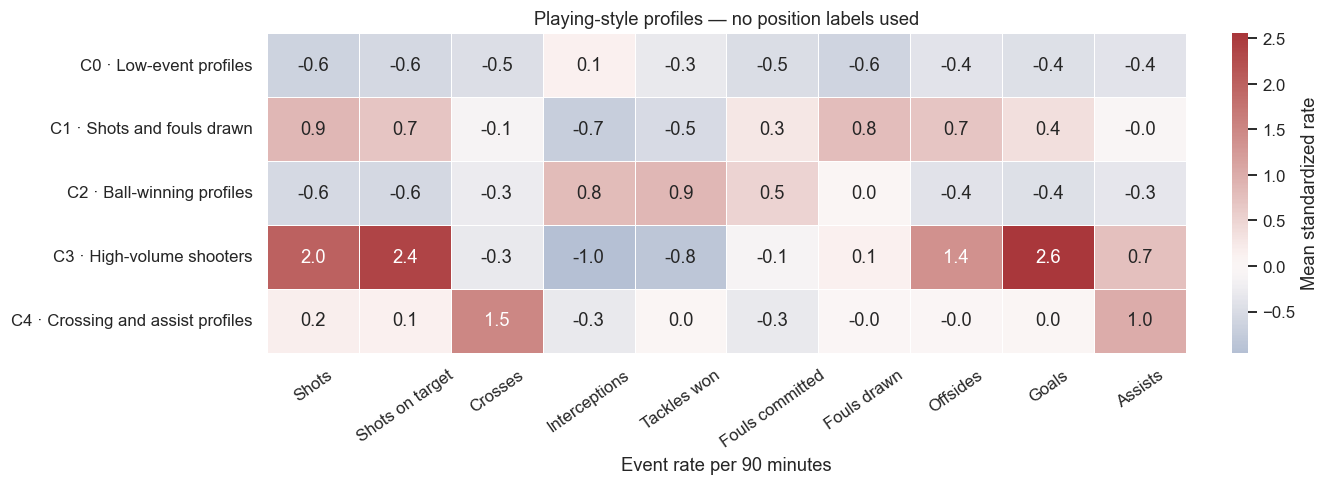

**Measured profiles.** **C0 (Low-event profiles)**: Interceptions +0.12 SD, Tackles won -0.29 SD; **C1 (Shots and fouls drawn)**: Shots +0.87 SD, Fouls drawn +0.79 SD; **C2 (Ball-winning profiles)**: Tackles won +0.86 SD, Interceptions +0.80 SD; **C3 (High-volume shooters)**: Goals +2.55 SD, Shots on target +2.37 SD; **C4 (Crossing and assist profiles)**: Crosses +1.51 SD, Assists +1.02 SD. “Most elevated” is a relative ranking, not necessarily an above-average value. Low-event profiles describe fewer recorded events, not poor ability: off-ball work, passing, positioning, and team tactics are incompletely measured. Crossing/assist profiles should not be equated with a fully measured creativity construct.

In [9]:
cluster_ids = list(range(N_CLUSTERS))
z_profiles = pd.DataFrame(Z, columns=FEATURES).assign(cluster=labels).groupby('cluster').mean().reindex(cluster_ids)
rate_profiles = rate_inputs.assign(cluster=labels).groupby('cluster').mean().reindex(cluster_ids)
cluster_sizes = pd.Series(labels).value_counts().reindex(cluster_ids)

def profile_name(profile):
    # Descriptive rules use rates only; no official position label is inspected.
    if profile['Sh_p90'] > 1.2 and profile['SoT_p90'] > 1.2:
        return 'High-volume shooters'
    if profile['Crs_p90'] > .8:
        return 'Crossing and assist profiles' if profile['Ast_p90'] > .5 else 'Crossing specialists'
    if profile[['Int_p90', 'TklW_p90']].mean() > .45:
        return 'Ball-winning profiles'
    if profile['Sh_p90'] > .4 and profile['Fld_p90'] > .4:
        return 'Shots and fouls drawn'
    if profile.mean() < -.2:
        return 'Low-event profiles'
    if profile['Ast_p90'] > .6:
        return 'Assist-oriented profiles'
    return 'Mixed event profiles'

STYLE_NAMES = {int(c): profile_name(z_profiles.loc[c]) for c in cluster_ids}
STYLE_LABELS = {c: f'C{c} · {STYLE_NAMES[c]}' for c in cluster_ids}
cluster_description = pd.DataFrame({
    'Style': [STYLE_LABELS[c] for c in cluster_ids],
    'Players': cluster_sizes.to_numpy(),
    'Share': [f'{cluster_sizes[c]/len(frame):.1%}' for c in cluster_ids],
    'Most elevated events': [', '.join(FEATURE_LABELS[f] for f in z_profiles.loc[c].nlargest(3).index) for c in cluster_ids],
}).set_index('Style')
display(cluster_description)
fig, ax = plt.subplots(figsize=(12, 4.3), layout='constrained')
sns.heatmap(z_profiles.rename(index=STYLE_LABELS, columns=FEATURE_LABELS), center=0, cmap='vlag',
            annot=True, fmt='.1f', linewidths=.4, ax=ax, cbar_kws={'label': 'Mean standardized rate'})
ax.set(title='Playing-style profiles — no position labels used', xlabel='Event rate per 90 minutes', ylabel='')
ax.tick_params(axis='x', rotation=35)
finish(fig, 'cluster_event_profiles.png')

profile_notes = []
for c in cluster_ids:
    elevated = z_profiles.loc[c].nlargest(2)
    profile_notes.append(f'**C{c} ({STYLE_NAMES[c]})**: ' + ', '.join(
        f'{FEATURE_LABELS[f]} {v:+.2f} SD' for f, v in elevated.items()))
narrative('**Measured profiles.** ' + '; '.join(profile_notes) +
    '. “Most elevated” is a relative ranking, not necessarily an above-average value. '
    'Low-event profiles describe fewer recorded events, not poor ability: off-ball work, '
    'passing, positioning, and team tactics are incompletely measured. Crossing/assist '
    'profiles should not be equated with a fully measured creativity construct.')

### Are five groups strongly separated?

The silhouette coefficient compares within-cluster cohesion with separation from other
clusters in standardized space. Higher is better, but it tends to favor broad, compact
partitions. We evaluate 2–8 groups without using position labels. A weak five-group score
would favor reading the profiles as an exploratory subdivision of overlapping styles.

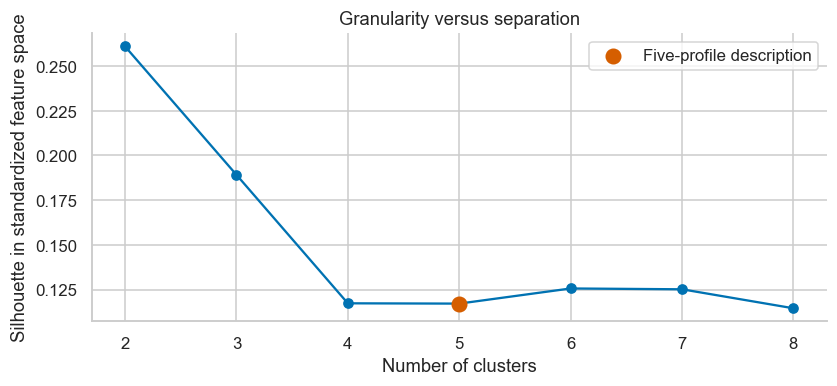

The five-profile silhouette is **0.117**; the strongest score in
this range occurs at **k=2** (0.261).
The broader partition is more cleanly separated; retain five as a finer exploratory description, not evidence of five discrete natural types.
The fraction of records with negative silhouette is **20.1%**,
identifying ambiguous boundaries rather than classification errors.

In [10]:
k_rows = []
with threadpool_limits(limits=1):
    for k in range(2, 9):
        current = labels if k == N_CLUSTERS else KMeans(n_clusters=k, n_init=30, random_state=SEED).fit_predict(Z)
        sizes = np.bincount(current)
        k_rows.append({'k': k, 'silhouette': silhouette_score(Z, current),
                       'smallest_cluster_n': int(sizes.min()), 'largest_cluster_n': int(sizes.max())})
k_comparison = pd.DataFrame(k_rows).set_index('k')
best_silhouette_k = int(k_comparison.silhouette.idxmax())
main_silhouette = float(k_comparison.loc[N_CLUSTERS, 'silhouette'])
player_silhouette = silhouette_samples(Z, labels)
fig, ax = plt.subplots(figsize=(7.5, 3.4), layout='constrained')
ax.plot(k_comparison.index, k_comparison.silhouette, 'o-', color='#0072B2')
ax.scatter([N_CLUSTERS], [main_silhouette], color='#D55E00', s=90, zorder=3, label='Five-profile description')
ax.set(xlabel='Number of clusters', ylabel='Silhouette in standardized feature space', title='Granularity versus separation')
ax.set_xticks(k_comparison.index)
ax.legend()
finish(fig, 'cluster_count_check.png')
narrative(f'''The five-profile silhouette is **{main_silhouette:.3f}**; the strongest score in
this range occurs at **k={best_silhouette_k}** ({k_comparison.loc[best_silhouette_k, 'silhouette']:.3f}).
{'The broader partition is more cleanly separated; retain five as a finer exploratory description, not evidence of five discrete natural types.' if best_silhouette_k < N_CLUSTERS else 'Five is not guaranteed to be the natural number of styles; the score depends on geometry and the included statistics.'}
The fraction of records with negative silhouette is **{np.mean(player_silhouette < 0):.1%}**,
identifying ambiguous boundaries rather than classification errors.''')

## 3. Compare the fixed clusters with official positions

Only now attach the first listed official position (`MF,FW` → MF). The left table asks which
positions occur **inside each cluster**; the right asks how each position is **distributed
across styles**. Different mixtures can show what a broad position label overlooks.

Adjusted Rand index (ARI) and normalized mutual information (NMI) describe agreement between
two different partitions. They are not classification accuracy, and official position is
not assumed to be ground truth for playing style. Low agreement alone would not establish
that the clusters are meaningful; the event profiles and stability checks supply context.

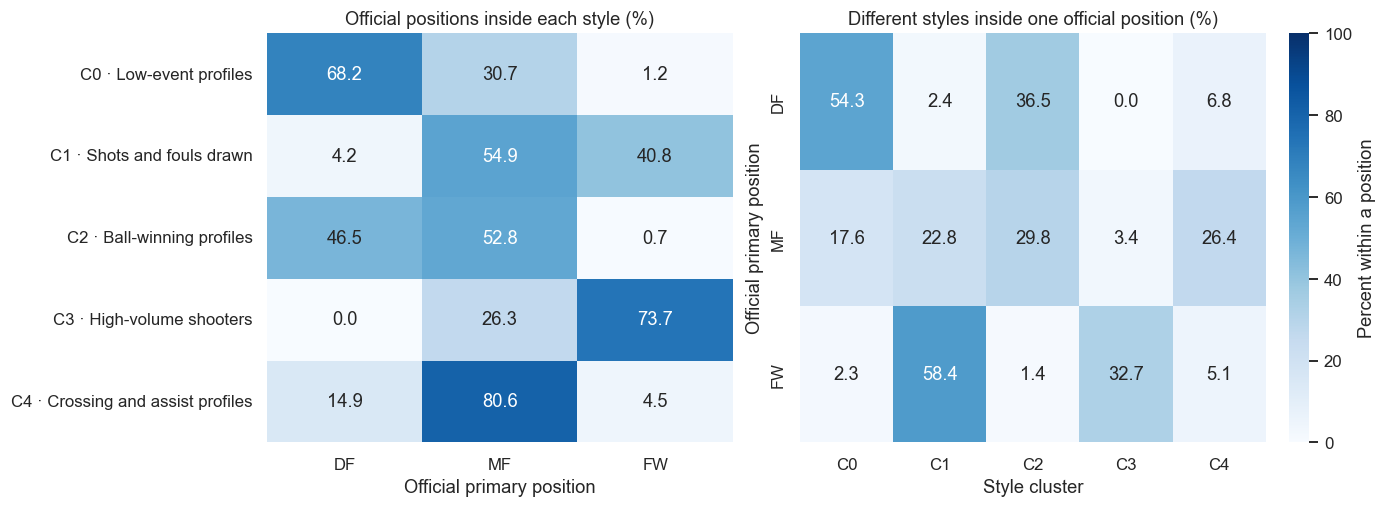

**Agreement:** ARI **0.144**, NMI **0.232**.
**DF**: C0 54.3%, C2 36.5%; 2 styles each contain at least 10% of this role **MF**: C2 29.8%, C4 26.4%; 4 styles each contain at least 10% of this role **FW**: C1 58.4%, C3 32.7%; 2 styles each contain at least 10% of this role. The same position spans different measured event patterns, while
some styles mix positions. This supports a more detailed descriptive view than one position
label, with the separation caveat above. It does not imply the official positions are wrong.

,MF records,Shots,Crosses,Interceptions,Tackles won,Assists
cluster,,,,,,
C0 · Low-event profiles,130,0.92,1.26,0.84,0.81,0.06
C1 · Shots and fouls drawn,168,2.38,1.92,0.56,0.75,0.09
C2 · Ball-winning profiles,220,0.92,1.19,1.37,1.45,0.06
C3 · High-volume shooters,25,3.70,2.33,0.39,0.53,0.37
C4 · Crossing and assist profiles,195,1.69,4.47,0.71,0.97,0.28


The MF-only table makes the comparison concrete: these players share the same official primary label but differ in crossing, shooting, ball winning, and assists. These differences are descriptive, and partially expected because the clusters were constructed from the same event statistics.

In [11]:
official_position = frame.Pos.astype('string').str.split(',', n=1).str[0].str.strip().str.upper()
assert official_position.isin(['DF', 'MF', 'FW']).all()
comparison = pd.DataFrame({'cluster': labels, 'position': official_position})
position_counts = pd.crosstab(comparison.cluster, comparison.position).reindex(index=cluster_ids, columns=['DF', 'MF', 'FW'], fill_value=0)
cluster_position_percent = position_counts.div(position_counts.sum(axis=1), axis=0)*100
position_style_percent = position_counts.T.div(position_counts.sum(axis=0), axis=0)*100
position_ari = adjusted_rand_score(official_position, labels)
position_nmi = normalized_mutual_info_score(official_position, labels)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), layout='constrained')
sns.heatmap(cluster_position_percent.rename(index=STYLE_LABELS), annot=True, fmt='.1f', vmin=0, vmax=100,
            cmap='Blues', ax=axes[0], cbar=False)
axes[0].set(title='Official positions inside each style (%)', xlabel='Official primary position', ylabel='')
sns.heatmap(position_style_percent.rename(columns=lambda c: f'C{c}'), annot=True, fmt='.1f', vmin=0, vmax=100,
            cmap='Blues', ax=axes[1], cbar_kws={'label': 'Percent within a position'})
axes[1].set(title='Different styles inside one official position (%)', xlabel='Style cluster', ylabel='Official primary position')
finish(fig, 'styles_and_official_positions.png')

role_notes = []
for position in ['DF', 'MF', 'FW']:
    distribution = position_style_percent.loc[position].sort_values(ascending=False)
    top_two = distribution.head(2)
    role_notes.append(f'**{position}**: ' + ', '.join(f'C{c} {share:.1f}%' for c, share in top_two.items()) +
                      f'; {(distribution >= 10).sum()} styles each contain at least 10% of this role')
narrative(f'''**Agreement:** ARI **{position_ari:.3f}**, NMI **{position_nmi:.3f}**.
{' '.join(role_notes)}. The same position spans different measured event patterns, while
some styles mix positions. This supports a more detailed descriptive view than one position
label, with the separation caveat above. It does not imply the official positions are wrong.''')

# Show how midfielders differ without changing the fitted clusters.
midfield_profiles = rate_inputs.loc[official_position.eq('MF')].assign(
    cluster=labels[official_position.eq('MF').to_numpy()]).groupby('cluster').mean()
midfield_counts = comparison.loc[comparison.position.eq('MF'), 'cluster'].value_counts()
mf_table = midfield_profiles[['Sh_p90', 'Crs_p90', 'Int_p90', 'TklW_p90', 'Ast_p90']].copy()
mf_table.insert(0, 'MF records', midfield_counts.reindex(mf_table.index))
display(mf_table.rename(index=STYLE_LABELS, columns=FEATURE_LABELS).round(2))
narrative('The MF-only table makes the comparison concrete: these players share the same '
          'official primary label but differ in crossing, shooting, ball winning, and assists. '
          'These differences are descriptive, and partially expected because the clusters '
          'were constructed from the same event statistics.')

## 4. Explore the interactive UMAP

UMAP projects the ten-dimensional standardized rates into two dimensions **without y**.
Clusters remain those fitted in the original standardized space. Switch between style and
official-position colors on the **same coordinates**, search for a player, filter by league
or playing time, or switch neighborhood settings. Hover gives the player, club, original
position, style, exposure, rates, silhouette, and resampling stability.

Nearby points have similar local event profiles; axis directions have no football units.
UMAP can distort distance and density, and apparent gaps are not proof of separate styles.
Changing neighborhood settings changes the map, not the assigned clusters. All filtered
views retain the original fit and scales. If your viewer blocks embedded interaction, open
`style_clustering_results/player_styles_umap.html` in a browser; it is self-contained offline.
The alternative layouts also vary minimum distance and one seed, so they illustrate display
sensitivity rather than isolate the effect of one parameter.

In [12]:
# Refit preprocessing on each 80% resample; align cluster IDs by maximum overlap.
stability_rows = []
match_counts = np.zeros(len(frame), dtype=float)
with threadpool_limits(limits=1):
    for seed in range(10):
        subset = np.random.default_rng(seed).choice(len(frame), size=int(.8*len(frame)), replace=False)
        resampled = cluster_pipeline(seed=seed).fit(rate_inputs.iloc[subset])
        alternate = resampled.predict(rate_inputs)
        overlap = pd.crosstab(labels, alternate).reindex(index=cluster_ids, columns=cluster_ids, fill_value=0).to_numpy()
        rows, cols = linear_sum_assignment(-overlap)
        mapping = dict(zip(cols, rows))
        aligned = np.array([mapping[c] for c in alternate])
        match_counts += aligned == labels
        stability_rows.append({'resample_seed': seed, 'resample_fraction': .8,
                                'ARI_to_full_partition': adjusted_rand_score(labels, alternate)})
stability = pd.DataFrame(stability_rows)
player_stability = match_counts/len(stability)

UMAP_SETTINGS = {
    '30 neighbors': {'n_neighbors': 30, 'min_dist': .15, 'random_state': SEED},
    '15 neighbors': {'n_neighbors': 15, 'min_dist': .05, 'random_state': 7},
    '50 neighbors': {'n_neighbors': 50, 'min_dist': .40, 'random_state': SEED},
}
embeddings, embedding_rows = {}, []
for name, settings in UMAP_SETTINGS.items():
    with threadpool_limits(limits=1):
        mapper = umap.UMAP(n_components=2, metric='euclidean', n_epochs=350, n_jobs=1,
                           compatibility_layout=True, **settings)
        embeddings[name] = mapper.fit_transform(Z)  # No target, age, minutes, name, or league supplied.
        local_preservation = trustworthiness(Z, embeddings[name], n_neighbors=15)
    embedding_rows.append({'layout': name, **settings, 'trustworthiness_at_15_neighbors': local_preservation})
embedding_diagnostics = pd.DataFrame(embedding_rows)
assert all(v.shape == (len(frame), 2) and np.isfinite(v).all() for v in embeddings.values())

In [13]:
def make_interactive_map(records, layouts, styles, colors):
    payload = []
    for i, row in records.iterrows():
        entry = {
            'player': str(row.Player), 'club': str(row.Squad), 'league': str(row.Comp),
            'position': str(row.official_position), 'original_position': str(row.Pos),
            'minutes': float(row.Min), 'cluster': int(row.cluster), 'style': str(row.style),
            'stability': float(row.assignment_stability), 'silhouette': float(row.silhouette),
        }
        entry.update({f: None if pd.isna(row[f]) else round(float(row[f]), 4) for f in FEATURES})
        payload.append(entry)
    data_json = json.dumps({'players': payload, 'layouts': {k: np.round(v, 5).tolist() for k, v in layouts.items()},
                            'styles': styles, 'colors': colors, 'featureLabels': FEATURE_LABELS}, ensure_ascii=False).replace('<', chr(92)+'u003c')
    template = r'''
<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Football player styles — interactive UMAP</title>
<style>
:root{font-family:system-ui,-apple-system,sans-serif;color:#172330;background:#f4f6f8}
*{box-sizing:border-box}body{margin:0;padding:24px}.wrap{max-width:1440px;margin:auto}
h1{font-size:28px;letter-spacing:-.7px;margin:0 0 6px}p{line-height:1.5;color:#526172;margin:0 0 18px}
.controls{display:flex;flex-wrap:wrap;gap:12px;align-items:end;padding:16px;background:white;border-radius:12px}
label{font-size:12px;font-weight:650;color:#435265;display:flex;flex-direction:column;gap:5px}
select,input,button{font:inherit;font-size:14px;border:1px solid #c5ced8;border-radius:6px;padding:9px;background:white;color:#172330}
input{min-width:200px}button{cursor:pointer;padding:10px 15px;background:#172f45;color:white;border-color:#172f45}
.count{font-size:13px;margin:12px 0;color:#435265}#style-map{height:620px;border-radius:12px;overflow:hidden;background:white}
.note{font-size:12px;margin:12px 0}.status{font-size:12px;color:#435265;margin-top:10px}
@media(max-width:650px){body{padding:12px}h1{font-size:23px}.controls{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:12px;align-items:start}label{min-width:0}label[for="player-search"],.controls button{grid-column:1/-1}select,input{min-width:0;width:100%}#style-map{height:620px}}
</style><script>__PLOTLY_JS__</script></head><body><main class="wrap">
<h1>Football playing styles</h1><p>Explore event profiles across players. Official positions are comparison labels; they were not used to fit the clusters or UMAP.</p>
<section class="controls" aria-label="Map controls">
<label for="color-mode">Color points by<select id="color-mode" data-testid="color-mode"><option value="cluster">Playing style</option><option value="position">Official position</option></select></label>
<label for="layout-mode">UMAP neighborhood<select id="layout-mode" data-testid="layout-mode"></select></label>
<label for="league-filter">League<select id="league-filter" data-testid="league-filter"><option value="all">All leagues</option></select></label>
<label for="minutes-filter">Minimum minutes<select id="minutes-filter" data-testid="minutes-filter"><option value="180">180</option><option value="450">450</option><option value="600">600</option></select></label>
<label for="player-search">Find player<input id="player-search" data-testid="player-search" placeholder="Type a player or club name" autocomplete="off"></label>
<button id="reset" data-testid="reset" type="button">Reset</button></section>
<div id="visible-count" class="count" role="status" aria-live="polite">Loading map…</div>
<div id="style-map" aria-label="Interactive UMAP scatter plot of football players"></div>
<p class="note">One point per player–club record. Hover for details. Drag to zoom, double-click to reset the view, and click legend entries to toggle groups. UMAP axes have no football units; gaps and density are not evidence of natural cluster boundaries.</p>
<div class="status" id="map-status">Preparing visualization…</div>
</main><script id="style-data" type="application/json">__DATA_JSON__</script><script>
const D=JSON.parse(document.getElementById('style-data').textContent);
const players=D.players, plot=document.getElementById('style-map');
const color=document.getElementById('color-mode'), layout=document.getElementById('layout-mode');
const league=document.getElementById('league-filter'), minutes=document.getElementById('minutes-filter');
const search=document.getElementById('player-search'), reset=document.getElementById('reset');
const number=v=>v==null?'missing':Number(v).toFixed(2);
const escapeText=s=>String(s).replace(/[&<>"']/g,c=>({'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;',"'":'&#39;'}[c]));
for(const name of Object.keys(D.layouts)){const o=document.createElement('option');o.value=name;o.textContent=name;layout.appendChild(o)}
for(const name of [...new Set(players.map(p=>p.league))].sort()){const o=document.createElement('option');o.value=name;o.textContent=name;league.appendChild(o)}
const positionColors={DF:'#0072B2',MF:'#009E73',FW:'#D55E00'};
function tooltip(p){
 let text='<b>'+escapeText(p.player)+'</b><br>'+escapeText(p.club)+' · '+escapeText(p.league);
 text+='<br>Official: '+escapeText(p.original_position)+' (primary '+escapeText(p.position)+')';
 text+='<br>Style: C'+p.cluster+' · '+escapeText(p.style)+'<br>Minutes: '+p.minutes.toFixed(0);
 for(const [f,label] of Object.entries(D.featureLabels)){text+='<br>'+label+'/90: '+number(p[f])}
 text+='<br>Resampling agreement: '+(p.stability*100).toFixed(0)+'%';
 text+='<br>Feature-space silhouette: '+number(p.silhouette);
 return text;
}
async function draw(){
 const query=search.value.trim().toLocaleLowerCase(), coords=D.layouts[layout.value];
 const shown=players.map((p,i)=>({p,i})).filter(({p})=>(league.value==='all'||p.league===league.value)&&p.minutes>=Number(minutes.value)&&(!query||(p.player+' '+p.club).toLocaleLowerCase().includes(query)));
 const groups=color.value==='cluster'?Object.keys(D.styles).map(Number):['DF','MF','FW'];
 const traces=groups.map(group=>{
  const data=shown.filter(({p})=>color.value==='cluster'?p.cluster===group:p.position===group);
  return {type:'scatter',mode:'markers',name:color.value==='cluster'?'C'+group+' · '+D.styles[group]:group,
    x:data.map(({i})=>coords[i][0]),y:data.map(({i})=>coords[i][1]),
    text:data.map(({p})=>tooltip(p)),customdata:data.map(({i})=>i),
    hovertemplate:'%{text}<extra></extra>',
    marker:{size:7,opacity:.72,color:color.value==='cluster'?D.colors[group]:positionColors[group]},
    showlegend:true};
 });
 const xmin=Math.min(...coords.map(p=>p[0])),xmax=Math.max(...coords.map(p=>p[0]));
 const ymin=Math.min(...coords.map(p=>p[1])),ymax=Math.max(...coords.map(p=>p[1]));
 await Plotly.react(plot,traces,{template:'plotly_white',margin:{l:55,r:20,t:20,b:55},
  xaxis:{title:{text:'UMAP 1'},zeroline:false,range:[xmin-.5,xmax+.5]},
  yaxis:{title:{text:'UMAP 2'},zeroline:false,range:[ymin-.5,ymax+.5]},
  legend:{orientation:'h',x:0,y:1.02,yanchor:'bottom',font:{size:11}},
  hovermode:'closest',dragmode:'zoom',uirevision:layout.value},
  {responsive:true,displaylogo:false,toImageButtonOptions:{filename:'football-player-styles'}});
 document.getElementById('visible-count').textContent=shown.length.toLocaleString()+' / '+players.length.toLocaleString()+' player records match filters · '+layout.value+' · '+(color.value==='cluster'?'colors show playing style':'colors show official position');
 document.getElementById('map-status').textContent=shown.length?'Map ready. Filters do not refit the clusters or embedding.':'No matching records. Clear the search or reset the filters.';
 plot.dataset.visiblePoints=String(shown.length);plot.dataset.colorMode=color.value;plot.dataset.ready='true';
}
for(const control of [color,layout,league,minutes])control.addEventListener('change',()=>draw());
search.addEventListener('input',()=>draw());
reset.addEventListener('click',()=>{color.value='cluster';layout.value='30 neighbors';league.value='all';minutes.value='180';search.value='';draw()});
new ResizeObserver(()=>{if(plot._fullLayout){Plotly.Plots.resize(plot)}}).observe(plot);
draw().catch(error=>{document.getElementById('map-status').textContent='Map could not render: '+error.message;console.error(error)});
</script></body></html>'''
    return template.replace('__PLOTLY_JS__', get_plotlyjs()).replace('__DATA_JSON__', data_json)

players = frame[['source_row', 'Player', 'Squad', 'Comp', 'Pos', 'Min']+FEATURES].copy()
players['official_position'] = official_position
players['cluster'] = labels
players['style'] = [STYLE_NAMES[c] for c in labels]
players['silhouette'] = player_silhouette
players['assignment_stability'] = player_stability
for name, coordinates in embeddings.items():
    slug = name.replace(' ', '_')
    players[f'umap_{slug}_1'] = coordinates[:, 0]
    players[f'umap_{slug}_2'] = coordinates[:, 1]
interactive_html = make_interactive_map(players, embeddings, STYLE_NAMES, PALETTE)
HTML_PATH = OUT/'player_styles_umap.html'
HTML_PATH.write_text(interactive_html, encoding='utf-8')
# Embedded offline HTML has the same controls as the standalone exported map.
display(HTML('<div><iframe title="Interactive player-style UMAP" srcdoc="'+html.escape(interactive_html, quote=True)+
             '" style="width:100%;height:960px;border:0" loading="lazy"></iframe></div>'))
narrative(f'Interactive standalone map: **{HTML_PATH.name}** in `style_clustering_results/`. '
          'The chart includes all records without downsampling; searches and filters are local to the page.')

Interactive standalone map: **player_styles_umap.html** in `style_clustering_results/`. The chart includes all records without downsampling; searches and filters are local to the page.

## 5. How stable are the styles, and what can we conclude?

Resampling changes 20% of the observations and refits the whole pipeline ten times. ARI
measures agreement with the full-sample partition. Per-player agreement aligns arbitrary
cluster numbers using maximum overlap; it is a descriptive stability score, **not a class
probability or confidence interval**. The repeated club records are not independent people,
so resampling also has that limitation. Sensitivity checks below change features and exposure.

In [14]:
stability_by_cluster = pd.DataFrame({'cluster': labels, 'agreement': player_stability}).groupby('cluster').agreement.agg(['mean', 'min'])
median_resample_ari = stability.ARI_to_full_partition.median()
stable_fraction = float(np.mean(player_stability >= .8))
display(stability_by_cluster.rename(index=STYLE_LABELS).round(3))
representative_rows = []
distances = cluster_model.named_steps['cluster'].transform(Z)
for c in cluster_ids:
    members = np.flatnonzero(labels == c)
    closest = members[np.argsort(distances[members, c])[:3]]
    for rank, i in enumerate(closest, 1):
        representative_rows.append({'Style': STYLE_LABELS[c], 'Rank': rank,
            'Player': frame.iloc[i].Player, 'Club': frame.iloc[i].Squad,
            'Official position': official_position.iloc[i], 'Minutes': frame.iloc[i].Min,
            'Distance to centroid': distances[i, c]})
representatives = pd.DataFrame(representative_rows)
display(representatives.drop(columns='Distance to centroid'))
narrative(f'''**Stability:** median resampling ARI is **{median_resample_ari:.3f}**;
**{stable_fraction:.1%}** of records retain their aligned cluster in at least 8/10 resamples.
The examples above are the three closest observed players to each centroid in standardized
space, not the most famous names or the highest raw event totals.

**Conclusion.** The five-profile description reveals differences within official positions
and similarities across them. {' '.join(role_notes)}. The broadest separation check favors
**k={best_silhouette_k}**, so the detailed profiles should be read as a useful exploratory
subdivision of an overlapping style landscape, rather than five proven natural categories.
UMAP makes this landscape inspectable; it does not validate the clusters.

These profiles cover only recorded shooting, crossing, ball winning, fouls, and goal
contributions in one snapshot. Team roles, possession, opponents, injuries, passing,
off-ball actions, source labeling, and limited minutes can explain differences. Source club
membership and underlying records are not independently verified. Additional seasons,
persistent player IDs, richer event data, and expert review would test whether the styles
are stable and tactically useful. No causal or future-performance claim follows from this
unsupervised description.''')

,mean,min
cluster,,
C0 · Low-event profiles,0.965,0.3
C1 · Shots and fouls drawn,0.954,0.3
C2 · Ball-winning profiles,0.904,0.3
C3 · High-volume shooters,0.947,0.2
C4 · Crossing and assist profiles,0.955,0.3


,Style,Rank,Player,Club,Official position,Minutes
0,C0 · Low-event profiles,1,Ville Koski,Alavés,DF,909.0
1,C0 · Low-event profiles,2,Luka Lochoshvili,Köln,DF,616.0
2,C0 · Low-event profiles,3,José Luis García Vayá,Valencia,DF,925.0
3,C1 · Shots and fouls drawn,1,Hugo Bolin,Gladbach,MF,558.0
4,C1 · Shots and fouls drawn,2,Amar Ahmed,Lecce,FW,370.0
5,C1 · Shots and fouls drawn,3,Enes Ünal,Getafe,FW,727.0
6,C2 · Ball-winning profiles,1,Ilaix Moriba,Celta Vigo,MF,807.0
7,C2 · Ball-winning profiles,2,Valentin Rongier,Rennes,MF,725.0
8,C2 · Ball-winning profiles,3,Jon Martin,Real Sociedad,DF,816.0
9,C3 · High-volume shooters,1,Younes Ebnoutalib,Frankfurt,FW,565.0


**Stability:** median resampling ARI is **0.844**;
**91.2%** of records retain their aligned cluster in at least 8/10 resamples.
The examples above are the three closest observed players to each centroid in standardized
space, not the most famous names or the highest raw event totals.

**Conclusion.** The five-profile description reveals differences within official positions
and similarities across them. **DF**: C0 54.3%, C2 36.5%; 2 styles each contain at least 10% of this role **MF**: C2 29.8%, C4 26.4%; 4 styles each contain at least 10% of this role **FW**: C1 58.4%, C3 32.7%; 2 styles each contain at least 10% of this role. The broadest separation check favors
**k=2**, so the detailed profiles should be read as a useful exploratory
subdivision of an overlapping style landscape, rather than five proven natural categories.
UMAP makes this landscape inspectable; it does not validate the clusters.

These profiles cover only recorded shooting, crossing, ball winning, fouls, and goal
contributions in one snapshot. Team roles, possession, opponents, injuries, passing,
off-ball actions, source labeling, and limited minutes can explain differences. Source club
membership and underlying records are not independently verified. Additional seasons,
persistent player IDs, richer event data, and expert review would test whether the styles
are stable and tactically useful. No causal or future-performance claim follows from this
unsupervised description.

## Appendix A. Sensitivity and technical diagnostics

These checks qualify the main interpretation. Re-cluster using log-compressed rates, fewer
correlated shooting inputs, all sixteen available event rates, and a 450-minute cohort.
Compare cluster assignments only on common records. Each configuration fits its own imputer
and scaler and keeps k=5. ARI differences quantify dependence on modeling choices, rather
than identify which configuration is objectively correct. No official labels enter these fits.

,configuration,n_records,n_features,ARI_to_core_on_common_rows,silhouette_in_own_feature_space,smallest_cluster_n
0,"Core rates, log1p then standardize",1484,10,0.502,0.115,209
1,Drop shots on target and goals,1484,8,0.712,0.136,129
2,All 16 event rates,1484,16,0.399,0.139,14
3,"Core rates, minimum 450 minutes",860,10,0.722,0.143,52


,silhouette,smallest_cluster_n,largest_cluster_n
k,,,
2,0.261,503,981
3,0.189,317,790
4,0.117,305,491
5,0.117,95,424
6,0.126,98,444
7,0.125,70,405
8,0.115,62,351


,resample_seed,resample_fraction,ARI_to_full_partition
0,0,0.8,0.924
1,1,0.8,0.799
2,2,0.8,0.793
3,3,0.8,0.960
4,4,0.8,0.804
5,5,0.8,0.958
6,6,0.8,0.831
7,7,0.8,0.880
8,8,0.8,0.858
9,9,0.8,0.735


,layout,n_neighbors,min_dist,random_state,trustworthiness_at_15_neighbors
0,30 neighbors,30,0.15,42,0.897
1,15 neighbors,15,0.05,7,0.918
2,50 neighbors,50,0.40,42,0.868


Silhouettes from different feature spaces are not directly comparable as an objective model ranking. Adding sparse rare events can create small incident-driven clusters; feature choice is therefore part of the substantive definition of style. The 450-minute comparison also changes the cohort, not only measurement reliability.

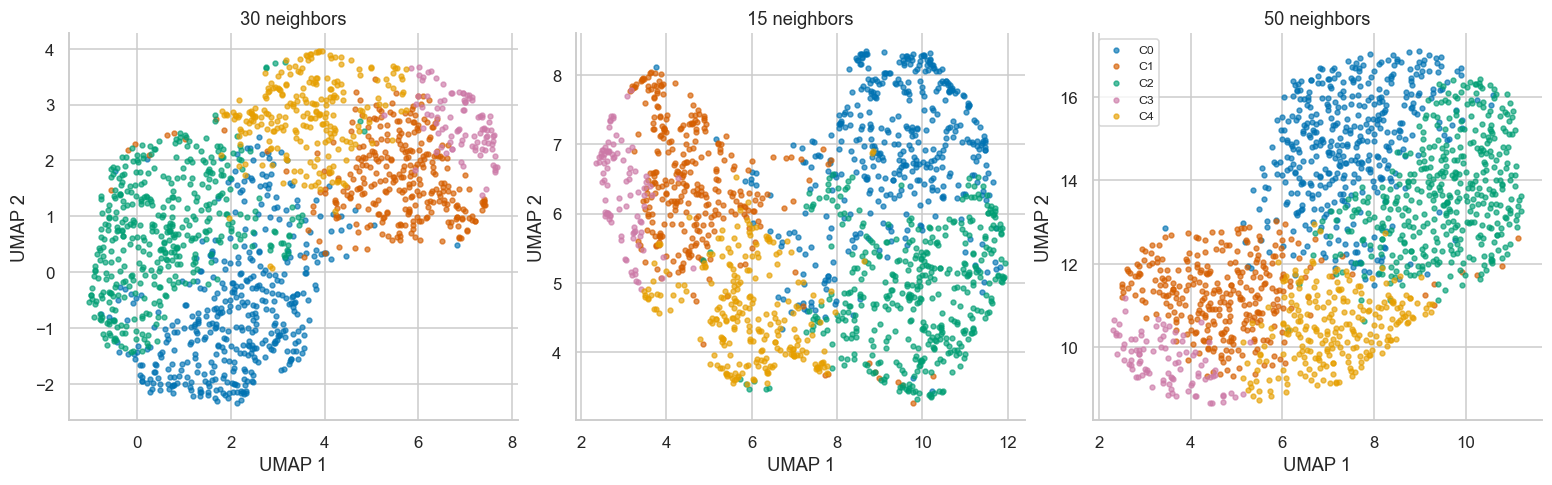

In [15]:
sensitivity_rows = []
sensitivity_inputs = {
    'Core rates, log1p then standardize': np.log1p(rate_inputs),
    'Drop shots on target and goals': rate_inputs.drop(columns=['SoT_p90', 'Gls_p90']),
    'All 16 event rates': frame[[f'{c}_p90' for c in CORE_COUNTS+EXTRA_COUNTS]],
    'Core rates, minimum 450 minutes': rate_inputs.loc[frame.Min.ge(450)],
}
with threadpool_limits(limits=1):
    for name, inputs in sensitivity_inputs.items():
        model = cluster_pipeline().fit(inputs)
        current = model.named_steps['cluster'].labels_
        current_z = model.named_steps['prepare'].transform(inputs)
        common = inputs.index.to_numpy()
        sizes = np.bincount(current)
        sensitivity_rows.append({'configuration': name, 'n_records': len(inputs),
            'n_features': inputs.shape[1], 'ARI_to_core_on_common_rows': adjusted_rand_score(labels[common], current),
            'silhouette_in_own_feature_space': silhouette_score(current_z, current),
            'smallest_cluster_n': int(sizes.min())})
sensitivities = pd.DataFrame(sensitivity_rows)
display(sensitivities.round(3))
display(k_comparison.round(3))
display(stability.round(3))
display(embedding_diagnostics.round(3))
narrative('Silhouettes from different feature spaces are not directly comparable as an '
          'objective model ranking. Adding sparse rare events can create small incident-driven '
          'clusters; feature choice is therefore part of the substantive definition of style. '
          'The 450-minute comparison also changes the cohort, not only measurement reliability.')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), layout='constrained')
for ax, (name, xy) in zip(axes, embeddings.items()):
    for c in cluster_ids:
        mask = labels == c
        ax.scatter(xy[mask, 0], xy[mask, 1], color=PALETTE[c], s=10, alpha=.65, label=f'C{c}')
    ax.set(title=name, xlabel='UMAP 1', ylabel='UMAP 2')
axes[-1].legend(fontsize=8)
finish(fig, 'umap_layout_sensitivity.png')

## Appendix B. Reproducibility and exports

Every table uses calculated values. Cluster IDs are arbitrary and names are post-hoc event
descriptions. The manifest records versions, input hash, feature lists, settings, and runtime.
The player export restores identifiers and positions **only as metadata** for exploration;
it is not a feature matrix to feed back into the unsupervised model. A separate standardized
feature export contains the actual clustering inputs, in matching row order.

In [16]:
assert not (set(cluster_model.feature_names_in_) & FORBIDDEN)
assert len(players) == len(labels) == len(Z) == sum(cluster_sizes)
assert np.isfinite(Z).all() and set(np.unique(labels)) == set(cluster_ids)
assert int(position_counts.to_numpy().sum()) == len(frame)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == SOURCE_HASH
versions = {'python': platform.python_version()}
for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'umap-learn', 'plotly', 'numba', 'pynndescent', 'llvmlite', 'matplotlib', 'seaborn']:
    versions[package] = metadata.version(package)
display(pd.Series(versions, name='Version').to_frame())
if startup_warnings:
    display(pd.DataFrame([{'startup_warning': str(w.message)} for w in startup_warnings]))
tables = {
    'player_style_assignments': players,
    'standardized_clustering_features': pd.DataFrame(Z, columns=FEATURES),
    'cluster_description': cluster_description.reset_index(),
    'cluster_profiles_standardized': z_profiles.reset_index(),
    'cluster_profiles_per90': rate_profiles.reset_index(),
    'cluster_position_counts': position_counts.reset_index(),
    'cluster_position_percent': cluster_position_percent.reset_index(),
    'position_style_percent': position_style_percent.reset_index(),
    'midfielder_event_profiles': mf_table.reset_index(),
    'representative_players': representatives,
    'cluster_count_diagnostics': k_comparison.reset_index(),
    'resampling_stability': stability,
    'feature_and_minutes_sensitivity': sensitivities,
    'umap_diagnostics': embedding_diagnostics,
}
for name, table in tables.items():
    table.to_csv(OUT/f'{name}.csv', index=False)
manifest = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(), 'source': str(DATA_PATH),
    'source_sha256': SOURCE_HASH, 'n_records': len(frame), 'minimum_minutes': MIN_MINUTES,
    'clustering_inputs': FEATURES, 'excluded_metadata': sorted(FORBIDDEN),
    'clustering': 'KMeans in standardized rate space, n_init=30, random_state=42',
    'n_clusters': N_CLUSTERS, 'cluster_names': STYLE_NAMES,
    'position_labels_used_for_fitting': False, 'umap_settings': UMAP_SETTINGS,
    'umap_common_parameters': {'n_components': 2, 'metric': 'euclidean', 'n_epochs': 350,
                               'n_jobs': 1, 'compatibility_layout': True},
    'main_silhouette': main_silhouette, 'best_silhouette_k_in_checked_range': best_silhouette_k,
    'position_ARI': position_ari, 'position_NMI': position_nmi,
    'median_resampling_ARI': float(median_resample_ari),
    'versions': versions, 'elapsed_seconds': perf_counter()-STARTED,
    'interactive_map': str(HTML_PATH),
}
(OUT/'clustering_manifest.json').write_text(json.dumps(manifest, indent=2))
print(f'All checks passed. Results: {OUT.resolve()}')
print(f'Elapsed analysis time: {(perf_counter()-STARTED)/60:.2f} minutes')

,Version
python,3.10.13
numpy,1.26.4
pandas,2.3.2
scipy,1.15.3
scikit-learn,1.7.2
umap-learn,0.6.0
plotly,7.1.0
numba,0.60.0
pynndescent,0.7.0
llvmlite,0.43.0


All checks passed. Results: /Users/zaiddib/Desktop/Artificial Intelligence Spain/Final/style_clustering_results
Elapsed analysis time: 0.14 minutes


## References

- [UMAP: clustering guidance](https://umap-learn.readthedocs.io/en/latest/clustering.html)
  — density and false-gap limitations; why clustering is performed in original standardized space here.
- [UMAP: parameter interpretation](https://umap-learn.readthedocs.io/en/latest/parameters.html)
  — neighborhood size and minimum distance affect the display.
- [UMAP: reproducibility](https://umap-learn.readthedocs.io/en/latest/reproducibility.html)
  — seeded stochastic fitting and numerical implementation affect reproducibility.
- [scikit-learn: clustering evaluation](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation)
  — silhouette and agreement measures answer different questions.
- [Plotly: standalone HTML](https://plotly.com/python-api-reference/generated/plotly.io.write_html.html)
  — interactive charts can include their JavaScript library for offline use.

The original full CSV was supplied through `archive.zip`. It has no match-level dates or
persistent player ID; this notebook makes no claim to independently authenticate it.